In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

In [98]:
SEED: int = 42

## 3 (a)

**Data visualization:** You are given a pre-generated dataset with training, validation, and testing splits. Begin by visualizing the training data. The dataset corresponds to samples (x1,x2,y) and you can be assured that (x1,x2) are each bounded between [−3,3]. You can either generate a 2D grid-plot where the y value is represented by a color at different (x1,x2) locations, or a 3D plot where we visualize the response y on the z-axis.

In [99]:
train = pd.read_csv('../data/train.csv')
test  = pd.read_csv('../data/test.csv')
val   = pd.read_csv('../data/val.csv')

In [100]:
train.sample(3)

,x1,x2,y
291,1.398767,0.631361,0.937836
417,0.882118,-1.501523,1.970380
419,2.759397,-0.042518,0.487830


In [101]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      600 non-null    float64
 1   x2      600 non-null    float64
 2   y       600 non-null    float64
dtypes: float64(3)
memory usage: 14.2 KB


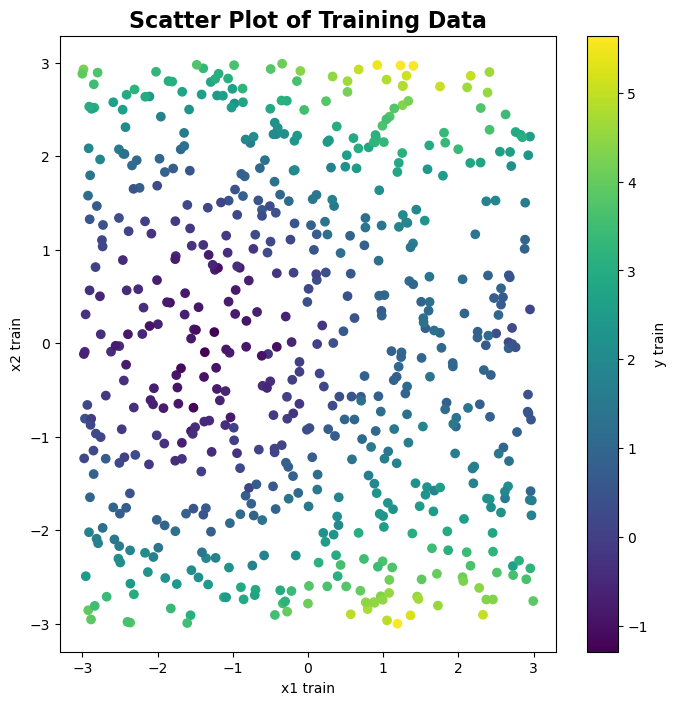

In [102]:
plt.figure(figsize=(8, 8))

sc = plt.scatter(train['x1'], train['x2'], c = train['y'], cmap='viridis')

plt.title('Scatter Plot of Training Data', fontweight='bold', fontsize=16)
plt.xlabel('x1 train')
plt.ylabel('x2 train')

cbar = plt.colorbar(sc)
cbar.set_label('y train')

plt.show()

## 3 (b)

**Random Kitchen Sink with Ridge Regression:** Implement and fit an RKS model to the given dataset with ridge regression. You will need to vary one of the key hyperparameters while keeping others fixed at reasonable defaults. Possible hyperparameters include:
- the number of random features h,
- the kernel scale parameter σ, or
- the ridge regularization strength λ.

Perform a hyperparameter sweep over your chosen parameter and record both the training and validation losses (MSE). Plot the losses as a function of the hyperparameter (two plots, one for training and one for validation loss), and select the best hyper-param based on the validation loss.

In [103]:
from models import rks_sweep, RandomKitchenSinks

In [104]:
# Fix h and sigma, vary lambda

h       = 500
sigma   = 1
lambda_ = np.concatenate((
    np.linspace(1e-3, 1, 10),       # Very small values for lambda
    np.linspace(1, 20, 10),         # Small to medium values for lambda
    np.linspace(20, 100, 10),       # Large values for lambda
    np.linspace(100, 500, 50)       # Very large values for lambda
))

params = [(h, sigma, lam) for lam in lambda_]

In [105]:
x_cols = ['x1', 'x2']
y      = 'y'

X_tr   = train[x_cols]
X_val  = val[x_cols]
X_te   = test[x_cols]

y_tr   = train[y].values
y_val  = val[y].values

In [106]:
rks_best_model, rks_best_params, rks_best_val_mse, rks_loss = rks_sweep(
    params = params, 
    X_tr = X_tr, 
    y_tr = y_tr, 
    X_val = X_val, 
    y_val = y_val,
    seed = SEED,
)

RKS Param Sweep: 100%|██████████| 80/80 [00:05<00:00, 15.10it/s]


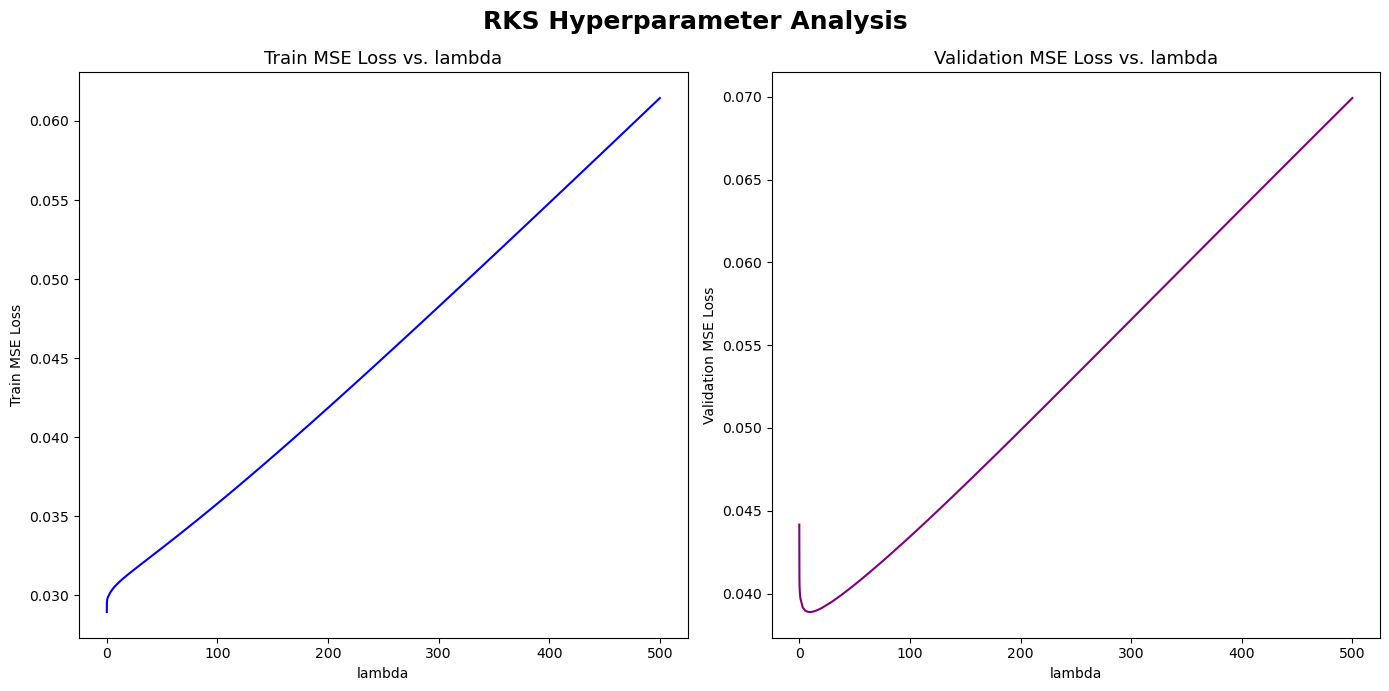

In [107]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
ax1.plot(lambda_, rks_loss['tr'], color='blue')
ax1.set_title("Train MSE Loss vs. lambda", fontsize=13)
ax1.set_xlabel("lambda")
ax1.set_ylabel("Train MSE Loss")

ax2.plot(lambda_, rks_loss['val'], color='purple')
ax2.set_title("Validation MSE Loss vs. lambda", fontsize=13)
ax2.set_xlabel("lambda")
ax2.set_ylabel("Validation MSE Loss")

plt.suptitle("RKS Hyperparameter Analysis", fontweight = 'bold', fontsize = 18)
plt.tight_layout()
plt.show()

In [108]:
print(f"Best Hyperparameter (lambda): {rks_best_params[-1]:.4f}")

Best Hyperparameter (lambda): 9.4444


## 3 (c)

**1-Hidden Layer Multi-Layer Perceptron:** Next, fit the same dataset using a one-hidden-layer MLP implemented in PyTorch or Jax (the provided starter code is in PyTorch). As before, you will choose one hyperparameter to vary (for example, the hidden layer dimension, learning rate, or batch size) and keep other hyperparameters fixed at default values. Plot the training and validation losses over the sweep and determine the best-performing configuration based on the validation loss.

In [109]:
from models import mlp_sweep, MLP

In [110]:
X_tr_t  = torch.tensor(train[x_cols].values, dtype=torch.float32)
X_val_t = torch.tensor(val[x_cols].values,   dtype=torch.float32)
X_te_t  = torch.tensor(test[x_cols].values,  dtype=torch.float32)

y_tr_t   = torch.Tensor(train[y].values).float()
y_val_t  = torch.Tensor(val[y].values).float()

In [111]:
# Fix learning rate and batch size (and all other params), vary hidden layer dimensions

epochs = 100
bias = True
lr  = 1e-3                                                                          
bs  = 64                                                                            
hds = 2 ** np.arange(1, 13) # 2, 4, 8, ..., 4096      
params = [(d_h, lr, bs, bias, epochs) for d_h in hds]

mlp_best_model, mlp_best_params, mlp_best_val_mse, mlp_loss = mlp_sweep(
    params = params,
    X_tr = X_tr_t,
    y_tr = y_tr_t,
    X_val = X_val_t,
    y_val = y_val_t,
    seed = SEED,
)

MLP Param Sweep: 100%|██████████| 12/12 [00:05<00:00,  2.32it/s]


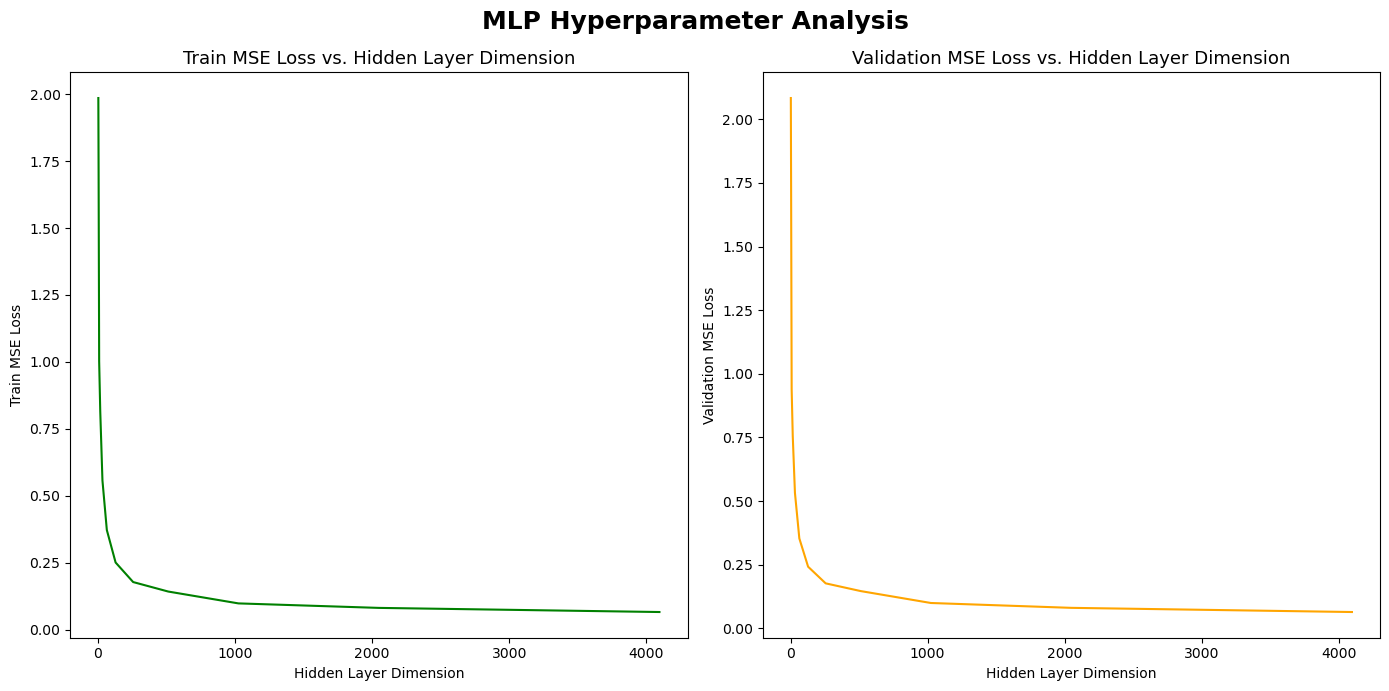

In [112]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
ax1.plot(hds, mlp_loss['tr'], color='green')
ax1.set_title("Train MSE Loss vs. Hidden Layer Dimension", fontsize=13)
ax1.set_xlabel("Hidden Layer Dimension")
ax1.set_ylabel("Train MSE Loss")

ax2.plot(hds, mlp_loss['val'], color='orange')
ax2.set_title("Validation MSE Loss vs. Hidden Layer Dimension", fontsize=13)
ax2.set_xlabel("Hidden Layer Dimension")
ax2.set_ylabel("Validation MSE Loss")

plt.suptitle("MLP Hyperparameter Analysis", fontweight = 'bold', fontsize = 18)
plt.tight_layout()
plt.show()

In [113]:
print(f"Best Hyperparameter (hidden layer dim): {mlp_best_params[0]:.0f}")

Best Hyperparameter (hidden layer dim): 4096


In [114]:
print(f"Best MLP Configuration", mlp_best_model.config)

Best MLP Configuration {'in_dim': 2, 'hidden_dim': 4096, 'out_dim': 1, 'bias': True, 'batch_size': 64, 'epochs': 100, 'learning_rate': 0.001, 'seed': 42}


## 3 (d)

**Comparison and visualization:** Using the best-performing hyperparameters from the previous steps, refit both models and report the validation loss (MSE) of each. Discuss which approach performs better and why. The provided test.csv is unlabeled (it contains only x1,x2): produce predictions from both models on it and submit them as two CSV files, rks_test_predictions.csv and mlp_test_predictions.csv, one prediction per row in the same order as test.csv. Finally, visualize the fitted functions from the two models over the input space (we provide an example function to do this). Compare these surfaces with your visualization of the training data from part (a), and qualitatively explain how each model captures the underlying structure of the data.

In [115]:
print(f"RKS Validation MSE Loss: {rks_best_val_mse:.4f}")

RKS Validation MSE Loss: 0.0389


In [116]:
print(f"MLP Validation MSE Loss: {mlp_best_val_mse:.4f}")

MLP Validation MSE Loss: 0.0644


### Discussion

Empirically, based on mean squared error, our RKS model outperforms our MLP model. We can gain intuition about why this may be the case by observing the training data. We see that the target ($y_i$) varies periodically in $x_1$ and is parabolic in $x_2$. By construction, the RKS model captures periodicity in our training data, while the ReLU in our MLP is not, by definition, a periodic function. Additionally, when training our MLP, we are applying an optimization algorithm, whereas when optimizing RKS, we can defer to a closed-form solution. Using an optimization algorithm introduces room for error (e.g. our MLP may be underfit).

In [117]:
rks_test_predictions = rks_best_model.predict(X_te)
mlp_test_predictions = mlp_best_model.predict(X_te_t)

np.savetxt("saved_data/rks_test_predictions.csv", rks_test_predictions, delimiter=",")
np.savetxt("saved_data/mlp_test_predictions.csv", mlp_test_predictions, delimiter=",")

In [118]:
from plotting import plot_surface_2d

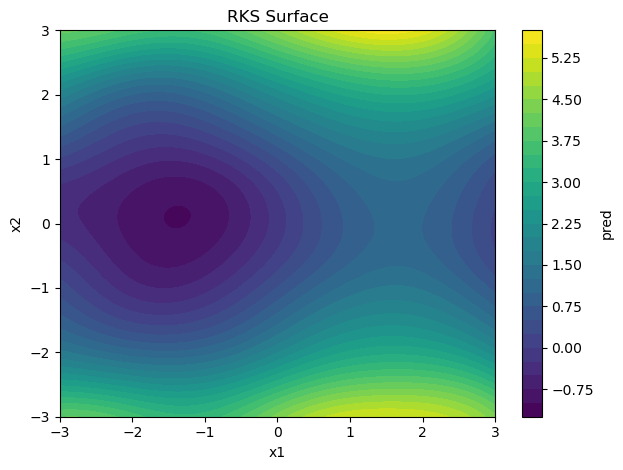

In [119]:
plot_surface_2d(
    model_fn = rks_best_model.predict,
    xlim     = (-3, 3), 
    ylim     = (-3, 3),
    title    = "RKS Surface",
)

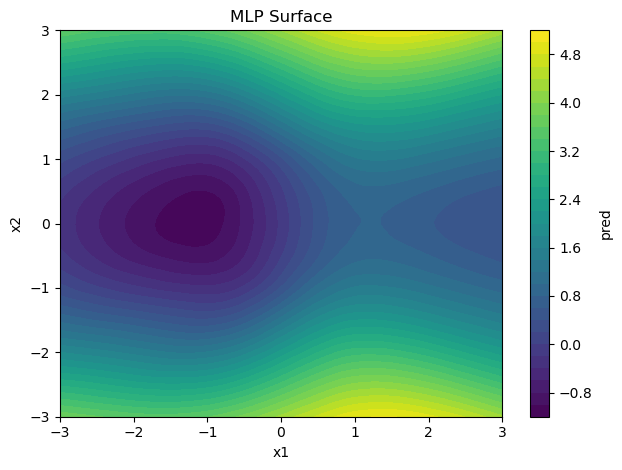

In [120]:
plot_surface_2d(
    model_fn = mlp_best_model,
    xlim     = (-3, 3), 
    ylim     = (-3, 3),
    title    = "MLP Surface",
)

### Discussion:

Qualitatively, we can observe that both models generate a smooth function that resembles the underlying structure of our training data. The contours form a saddle, with a basin containing a local minimum near $x_1 \approx -1.5$ and $x_2 \approx 0$. Both surfaces are very similar, with each model capturing the periodic (oscillatory) nature of the target with respect to $x_1$ and the parabolic (convex) nature of the target with respect to $x_2$.

- RKS: The $\sin{(\cdot)}$ and $\cos{(\cdot)}$ capture periodicity, and the convexity in $x_2$ is captured through all the linear combinations of low-frequency features.

- MLP: From class, we know that an MLP is a universal function approximator with just ReLU; therefore, we know that ReLU applied to a linear combination of the features will approximate the observed nonlinearities.